In [7]:
!pip install textblob wordcloud nltk -q

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from wordcloud import WordCloud

from nltk.corpus import stopwords
import string
import re

from textblob import TextBlob

In [9]:

import nltk
nltk.download('stopwords')
nltk.download('punkt')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [11]:
df = pd.read_csv("/content/Reviews.csv", engine='python', on_bad_lines='skip')

In [12]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 386349 entries, 0 to 386348
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      386349 non-null  int64 
 1   ProductId               386349 non-null  object
 2   UserId                  386349 non-null  object
 3   ProfileName             386331 non-null  object
 4   HelpfulnessNumerator    386349 non-null  int64 
 5   HelpfulnessDenominator  386349 non-null  int64 
 6   Score                   386349 non-null  int64 
 7   Time                    386349 non-null  int64 
 8   Summary                 386327 non-null  object
 9   Text                    386349 non-null  object
dtypes: int64(5), object(5)
memory usage: 29.5+ MB


In [14]:
df = df[['Score','Summary','Text']]


In [15]:
stop_words = set(stopwords.words('english'))

def clean_text(text):

    text = text.lower()

    text = re.sub(r"http\S+"," ",text)

    text = re.sub(r"[^a-zA-Z]"," ",text)

    words = text.split()

    words = [w for w in words if w not in stop_words]

    return " ".join(words)

df["Clean_Text"] = df["Text"].apply(clean_text)

In [16]:
def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity

    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    return "Neutral"

df["Sentiment"] = df["Clean_Text"].apply(get_sentiment)

In [17]:
df["Sentiment"].value_counts()

,count
Sentiment,
Positive,339227
Negative,40124
Neutral,6998


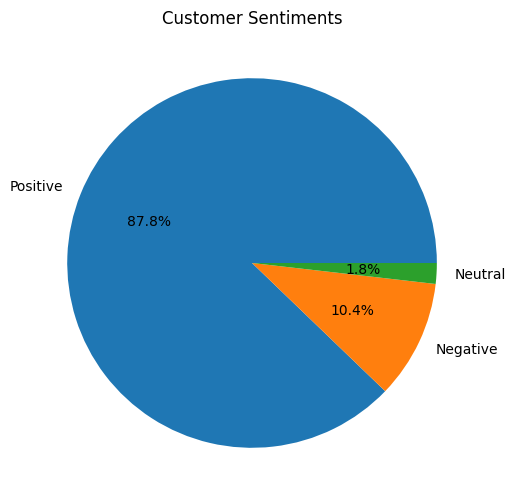

In [18]:
df["Sentiment"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6,6)
)

plt.title("Customer Sentiments")

plt.ylabel("")

plt.show()

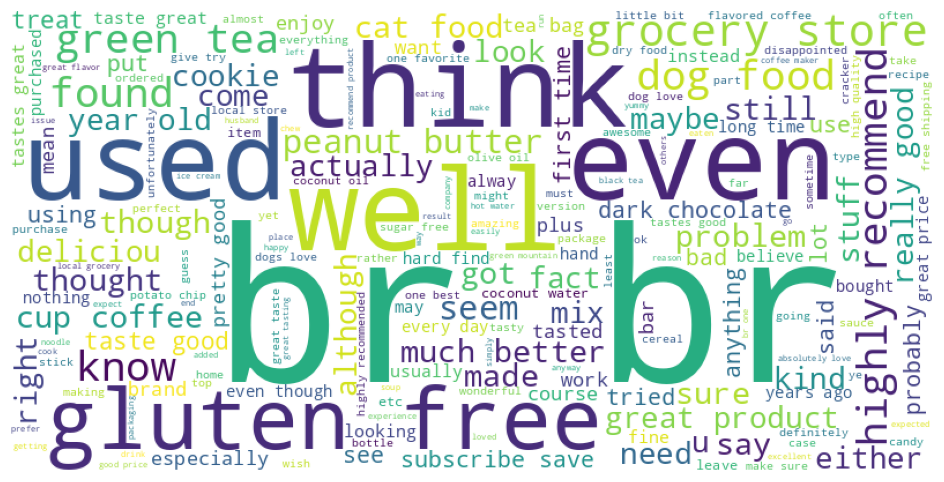

In [19]:

text = " ".join(df["Clean_Text"])

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(text)

plt.figure(figsize=(12,6))

plt.imshow(wordcloud)

plt.axis("off")

plt.show()

In [20]:
from collections import Counter

words = " ".join(df["Clean_Text"]).split()

counter = Counter(words)

common = counter.most_common(20)

common_df = pd.DataFrame(common, columns=["Word","Count"])

common_df

,Word,Count
0,br,443439
1,like,174905
2,good,136367
3,one,120959
4,taste,117271
5,great,113962
6,coffee,111590
7,product,104260
8,flavor,100486
9,tea,92594


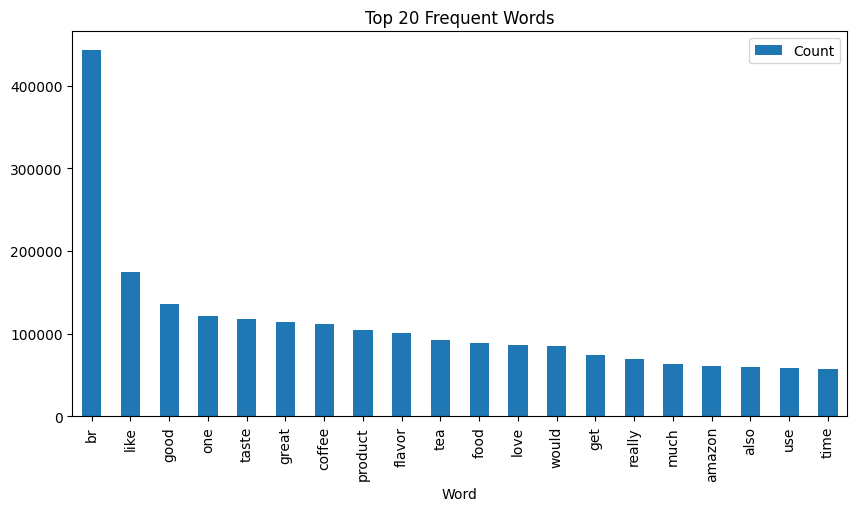

In [21]:
common_df.plot(
    x="Word",
    y="Count",
    kind="bar",
    figsize=(10,5)
)

plt.title("Top 20 Frequent Words")

plt.show()